In [1]:
# Create an App for User to Insert SMILES and ChemBel ID Data
# Then User Get The Bioactivity Data: PubChem Descriptor and pIC50

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import pickle

In [3]:
# Load The Dataset
df = pd.read_csv(r"D:\ANDINA\Course\Bioinformatics\Python\EGFR Drug Discovery\bioactivity_XY_dataset.csv")
df  # Display the first few rows of the DataFrame

,PubchemFP0,PubchemFP1,PubchemFP2,PubchemFP3,PubchemFP4,PubchemFP5,PubchemFP6,PubchemFP7,PubchemFP8,PubchemFP9,...,PubchemFP872,PubchemFP873,PubchemFP874,PubchemFP875,PubchemFP876,PubchemFP877,PubchemFP878,PubchemFP879,PubchemFP880,pIC50
0,1,1,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,7.387216
1,1,1,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,6.769551
2,1,1,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,5.031517
3,1,1,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,3.301030
4,1,1,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,2.522879
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
786,1,1,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,4.000000
787,1,1,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,4.000000
788,1,1,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,4.000000
789,1,1,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,4.000000


In [4]:
# Drop The pIC50 for X Data
X = df.drop(['pIC50'], axis = 1)
X

,PubchemFP0,PubchemFP1,PubchemFP2,PubchemFP3,PubchemFP4,PubchemFP5,PubchemFP6,PubchemFP7,PubchemFP8,PubchemFP9,...,PubchemFP871,PubchemFP872,PubchemFP873,PubchemFP874,PubchemFP875,PubchemFP876,PubchemFP877,PubchemFP878,PubchemFP879,PubchemFP880
0,1,1,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
1,1,1,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
2,1,1,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
3,1,1,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
4,1,1,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
786,1,1,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
787,1,1,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
788,1,1,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
789,1,1,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0


In [5]:
# Get The Y Data Consisting of pIC50
Y = df.iloc[:,-1]
Y

0      7.387216
1      6.769551
2      5.031517
3      3.301030
4      2.522879
         ...   
786    4.000000
787    4.000000
788    4.000000
789    4.000000
790    4.000000
Name: pIC50, Length: 791, dtype: float64

In [6]:
from sklearn.feature_selection import VarianceThreshold
def remove_low_variance(input_data, threshold = 0.1):
    selection = VarianceThreshold(threshold)
    selection.fit(input_data)
    return input_data[input_data.columns[selection.get_support(indices = True)]]

X = remove_low_variance(X, threshold = 0.1)
X

,PubchemFP2,PubchemFP12,PubchemFP15,PubchemFP16,PubchemFP18,PubchemFP19,PubchemFP20,PubchemFP23,PubchemFP33,PubchemFP37,...,PubchemFP779,PubchemFP784,PubchemFP791,PubchemFP797,PubchemFP798,PubchemFP800,PubchemFP805,PubchemFP814,PubchemFP821,PubchemFP824
0,0,1,1,1,1,0,0,1,0,1,...,0,0,0,0,0,0,0,0,0,0
1,1,1,1,1,1,1,0,1,0,1,...,0,0,0,0,0,0,0,0,0,0
2,1,1,1,1,0,0,0,0,0,0,...,0,0,1,0,0,1,0,0,1,0
3,0,0,1,0,1,1,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
4,0,0,0,0,1,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
786,1,1,1,0,1,1,1,0,0,0,...,0,0,0,0,1,1,0,0,1,0
787,1,1,1,0,1,1,1,0,0,0,...,0,0,0,0,0,0,1,0,1,0
788,1,1,1,0,1,1,1,0,0,0,...,1,0,0,1,0,0,0,0,1,0
789,1,1,1,0,1,1,1,0,0,0,...,0,0,0,0,0,1,0,0,1,0


In [11]:
# Convert X Data into CSV
X.to_csv('descriptor_list.csv', index = False)
X.to_csv('descriptor_output.csv', index = False)

In [8]:
# Create A Random Forest Regression Model
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

model = RandomForestRegressor(n_estimators = 500, random_state = 42)
model.fit(X, Y)
r2 = model.score(X, Y)
r2

0.9605516137407483

In [9]:
# Model Prediction
Y_pred = model.predict(X)
Y_pred

array([ 6.86017638,  7.06475238,  5.55093123,  3.29193972,  2.73932064,
        4.02559024,  6.27092585,  3.54861215,  5.70058624,  3.28643888,
        3.96676743,  4.85818533,  3.66412443,  8.43908605,  4.89835561,
        4.72592956,  3.46835948,  3.90093458,  4.85818533,  5.16166334,
        3.00329186,  3.14093918,  3.5499634 ,  3.50090663,  2.98223806,
        3.73416384,  7.53987613,  3.01357442,  3.56615252,  6.4477919 ,
        7.0110229 ,  5.01573983,  3.60956768,  4.71843915,  7.31775595,
        7.12497405,  3.49227223,  3.64928708,  7.5908349 ,  4.61283284,
        3.90093458,  8.19476838,  6.37873785,  3.67067316,  6.68522754,
        7.69235549,  6.4793203 ,  3.09421923,  4.13021278,  3.38863207,
        7.77285965,  5.29340546,  3.20089858,  3.26048822,  5.41197232,
        2.6731038 ,  2.97271788,  7.69235549,  3.28337606,  4.06369054,
        4.25173626,  3.1335441 ,  7.56481594,  3.54861215,  3.90093458,
        6.86168824,  7.5217278 ,  3.52271438,  4.05891576,  7.58

In [10]:
# Model Performance
print('Mean squared error (MSE): %.2f'
      % mean_squared_error(Y, Y_pred))
print('Coefficient of determination (R^2): %.2f'
      % r2_score(Y, Y_pred))

Mean squared error (MSE): 0.11
Coefficient of determination (R^2): 0.96


Text(0.5, 0, 'Experimental pIC50')

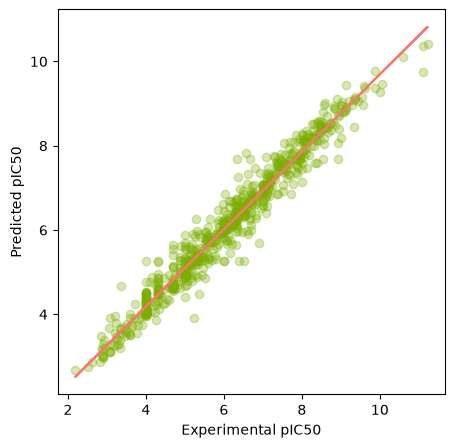

In [12]:
# Data Visualization
# Experimental vs Predicted pIC50 for Training Data
plt.figure(figsize=(5,5))
plt.scatter(x=Y, y=Y_pred, c="#7CAE00", alpha=0.3)

# Add trendline
# https://stackoverflow.com/questions/26447191/how-to-add-trendline-in-python-matplotlib-dot-scatter-graphs
z = np.polyfit(Y, Y_pred, 1)
p = np.poly1d(z)

plt.plot(Y,p(Y),"#F8766D")
plt.ylabel('Predicted pIC50')
plt.xlabel('Experimental pIC50')

In [13]:
# Save Model as Pickle Object
pickle.dump(model, open('EGFR_model.pkl', 'wb'))